In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import geopandas as gpd

In [2]:
# Styling matched to the MRC facet figure (ess-project/mrc_analysis/mrc/plotting.py:
# plot_mrc_facet). There, hue = basin identity and the variant reads off a lightness
# ramp PLUS a marker shape, so either channel alone identifies a series.
import matplotlib.colors as _mc

BASIN_COLORS = {"East River": "#0072B2", "Tuolumne River": "#D55E00"}
EAST_COLOR, TUOLUMNE_COLOR = BASIN_COLORS["East River"], BASIN_COLORS["Tuolumne River"]
_STEPS = (-0.45, 0.20, 0.68)

def _shade(hex_color, amount):
    r, g, b = _mc.to_rgb(hex_color)
    if amount >= 0:
        return tuple(c + (1.0 - c)*amount for c in (r, g, b))
    return tuple(c*(1.0 + amount) for c in (r, g, b))

_PALETTES = {
    "basin": {"East": [_shade(EAST_COLOR, s) for s in _STEPS],
              "Tuolumne": [_shade(TUOLUMNE_COLOR, s) for s in _STEPS]},
    "grey":  {"East": ["#2f2f2f", "#8a8a8a", "#d9d9d9"],
              "Tuolumne": ["#2f2f2f", "#8a8a8a", "#d9d9d9"]},
}
_HATCH, _W, _OFF = (None, None, None), 0.26, 0.27

# Same ramp positions and markers the facet uses for observed / baseline / adjusted.
# The two model steps were 0.05 and 0.38 -- only 0.33 of lightness apart, which on the
# Tuolumne orange left baseline and snowpatch nearly indistinguishable. Widened to 0.70,
# matching the 3-series ramp used for Fig 2 in result_viz_sandbox.
FACET_SHADE  = {"Observed": -0.45, "baseline": -0.28, "deep store": 0.42, "snowpatch": 0.42}
FACET_MARKER = {"Observed": "o",   "baseline": "s",  "deep store": "^", "snowpatch": "^"}

def model_style(basin, key):
    """(color, marker) for one model in one basin, consistent with the facet figure."""
    return _shade(BASIN_COLORS[basin], FACET_SHADE[key]), FACET_MARKER[key]

# The SWE-Q regression is a statistical benchmark, not a SUMMA run, so it keeps a
# neutral style in both basins rather than borrowing a basin hue.
# ...and it should not out-weigh the runs it is benchmarking: the near-black star at
# s=170 was the heaviest mark on the plot. Mid-grey, slightly smaller.
SWE_COLOR, SWE_MARKER = "#575757", "*"

# East-River dicts, kept under the original names so the East cell below is unchanged.
model_colors  = {k: _PALETTES["basin"]["East"][i] for i, k in enumerate(("baseline", "deep store"))}
model_markers = {k: FACET_MARKER[k]                 for k in ("baseline", "deep store")}
model_labels  = {"baseline": "baseline", "deep store": "deep store", "snowpatch": "snowpatch", "SWE-Q": "SWE-Q regression"}

# Tuolumne equivalents
tuo_model_colors  = {k: _PALETTES["basin"]["Tuolumne"][i] for i, k in enumerate(("baseline", "snowpatch"))}
tuo_model_markers = dict(model_markers)

In [3]:
# Shared plotting helpers for both basins.
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

def plot_annual_q_scatter(obs_wy_series, annual_q_dict, apr1_swe, obs_reg, *,
                          basin, combos=("baseline", "deep store", ),
                          highlight_wys=None, ax=None, title=None, legend_fontsize=14):
    """Modeled (x) vs observed (y) water-year total Q, in mm/yr.

    `obs_wy_series` and each `annual_q_dict[key]['annual_q']` are indexed by water year.
    `obs_reg` is a fitted sklearn LinearRegression mapping Apr-1 SWE -> annual Q; its
    predictions are drawn as a third "model" so the physical runs can be judged against
    a purely statistical benchmark.
    """
    highlight_wys = highlight_wys or {}
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 7))
    handles, all_x, all_y = [], [], []
    hi_pts = {wy: [] for wy in highlight_wys}

    for key in combos:
        col, mk = model_style(basin, key)
        sim = annual_q_dict[key]["annual_q"]
        xs, ys = [], []
        for wy, obs_q in obs_wy_series.items():
            if wy not in sim.index or np.isnan(sim.loc[wy]):
                continue
            xs.append(float(sim.loc[wy])); ys.append(float(obs_q))
            if wy in hi_pts:
                hi_pts[wy].append((xs[-1], ys[-1]))
        if not xs:
            continue
        ax.scatter(xs, ys, color=col, marker=mk, alpha=0.85, edgecolors="k",
                   linewidths=0.4, s=130 if mk == "^" else 55, zorder=4)
        all_x += xs; all_y += ys
        rmse = np.sqrt(np.mean((np.array(xs) - np.array(ys)) ** 2))
        pbias = 100 * np.sum(np.array(xs) - np.array(ys)) / np.sum(np.array(ys))
        handles.append(Line2D([0], [0], marker=mk, color="w", markerfacecolor=col,
                              markersize=9, markeredgecolor="k", markeredgewidth=0.5,
                              label=f"{key} \n(RMSE={rmse:.0f}, bias={pbias:+.0f}%)"))

    # SWE-Q regression benchmark
    sx, sy = [], []
    for wy, obs_q in obs_wy_series.items():
        if wy in apr1_swe.index and not np.isnan(apr1_swe[wy]):
            pred = obs_reg.coef_[0] * apr1_swe[wy] + obs_reg.intercept_
            sx.append(float(pred)); sy.append(float(obs_q))
            if wy in hi_pts:
                hi_pts[wy].append((sx[-1], sy[-1]))
    if sx:
        rmse = np.sqrt(np.mean((np.array(sx) - np.array(sy)) ** 2))
        pbias = 100 * np.sum(np.array(sx) - np.array(sy)) / np.sum(np.array(sy))
        ax.scatter(sx, sy, color=SWE_COLOR, marker=SWE_MARKER, s=140, edgecolors="k",
                   linewidths=0.5, alpha=0.9, zorder=5)
        handles.append(Line2D([0], [0], marker=SWE_MARKER, color="w",
                              markerfacecolor=SWE_COLOR, markersize=11,
                              markeredgecolor="k", markeredgewidth=0.5,
                              label=f"SWE-Q regression \n(RMSE={rmse:.0f}, bias={pbias:+.0f}%)"))
        all_x += sx; all_y += sy

    for wy, col in highlight_wys.items():
        pts = hi_pts.get(wy) or []
        if not pts:
            continue
        hx = [p[0] for p in pts]; hy = [p[1] for p in pts]
        ax.scatter(hx, hy, s=220, facecolors="none", edgecolors=col, linewidths=2.0, zorder=6)
        ax.annotate(f"WY{wy}", xy=(max(hx), hy[0]), xytext=(7, 0),
                    textcoords="offset points", fontweight="bold",
                    color=col, va="center", zorder=7)
        # handles.append(Line2D([0], [0], marker="o", color="w", markerfacecolor="none",
        #                       markersize=10, markeredgecolor=col, markeredgewidth=2.0,
        #                       label=f"WY{wy}"))

    lo, hi = min(min(all_x), min(all_y)) * 0.95, max(max(all_x), max(all_y)) * 1.05
    ax.plot([lo, hi], [lo, hi], "k--", lw=1.2, alpha=0.55, zorder=2)
    ax.set_aspect("equal")
    ax.legend(handles=handles, loc="upper left", framealpha=0.9, fontsize=legend_fontsize)
    ax.set_xlabel("Modeled WY Total Q  (mm/yr)")
    ax.set_ylabel("Observed WY Total Q  (mm/yr)")
    ax.grid(True, alpha=0.2)
    return ax


def bottom_quartile_subset(obs_wy_series, annual_q_dict, apr1_swe, obs_reg,
                           q=0.25, combos=("baseline", "deep store"), pad=0.06):
    """Water years whose OBSERVED total falls in the lowest `q` of the record.

    Returns (years, threshold, bbox) where bbox = (x0, x1, y0, y1) is the bounding box
    of every point those years contribute -- model runs AND the SWE-Q benchmark -- so
    the call-out on the full scatter frames exactly what the zoom panel shows.
    """
    thresh = float(obs_wy_series.quantile(q))
    wys = [wy for wy, v in obs_wy_series.items() if v <= thresh]
    xs, ys = [], []
    for wy in wys:
        ys.append(float(obs_wy_series.loc[wy]))
        for key in combos:
            sim = annual_q_dict[key]["annual_q"]
            if wy in sim.index and not np.isnan(sim.loc[wy]):
                xs.append(float(sim.loc[wy]))
        if wy in apr1_swe.index and not np.isnan(apr1_swe[wy]):
            xs.append(float(obs_reg.coef_[0] * apr1_swe[wy] + obs_reg.intercept_))
    if not xs:
        return wys, thresh, None
    dx, dy = (max(xs) - min(xs)) * pad, (max(ys) - min(ys)) * pad
    return wys, thresh, (min(xs) - dx, max(xs) + dx, min(ys) - dy, max(ys) + dy)

def top_quartile_subset(obs_wy_series, annual_q_dict, apr1_swe, obs_reg,
                        q=0.75, combos=("baseline", "deep store"), pad=0.06):
    """Water years whose OBSERVED total falls in the highest `q` of the record."""

    thresh = float(obs_wy_series.quantile(q))
    wys = [wy for wy, v in obs_wy_series.items() if v >= thresh]
    xs, ys = [], []
    for wy in wys:
        ys.append(float(obs_wy_series.loc[wy]))
        for key in combos:
            sim = annual_q_dict[key]["annual_q"]
            if wy in sim.index and not np.isnan(sim.loc[wy]):
                xs.append(float(sim.loc[wy]))
        if wy in apr1_swe.index and not np.isnan(apr1_swe[wy]):
            xs.append(float(obs_reg.coef_[0] * apr1_swe[wy] + obs_reg.intercept_))
    if not xs:
        return wys, thresh, None
    dx, dy = (max(xs) - min(xs)) * pad, (max(ys) - min(ys)) * pad
    return wys, thresh, (min(xs) - dx, max(xs) + dx, min(ys) - dy, max(ys) + dy)


def add_quartile_callout(ax, bbox, *, color="#444444", label=None, label_loc="above"):
    """Draw the call-out rectangle that the zoom panel below expands."""
    if bbox is None:
        return
    x0, x1, y0, y1 = bbox
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=color,
                           lw=1.6, ls=(0, (5, 3)), zorder=8))
    if label:
        ax.annotate(label, xy=(x1, y1), xytext=(6, 6), textcoords="offset points",
                    fontweight="bold", color=color, ha="left",
                    va="bottom", zorder=9)


# ---- common analysis window ----------------------------------------------------------
# Every panel is drawn on ONE year set per basin: water years in ANALYSIS_YEARS for which
# observed Q, Apr-1 SWE, and every model run all have data. A year missing from any member
# is dropped from all of them, so the RMSE/bias numbers in the legends are strictly
# comparable rather than each being computed over whatever that series happened to cover.
ANALYSIS_YEARS = (1986, 2024)

def common_years(obs_wy, apr1_swe, annual_q_dict, window=ANALYSIS_YEARS, verbose=True):
    """Water years inside `window` present in the observations, the SWE record and EVERY run."""
    lo, hi = window
    full = set(range(lo, hi + 1))
    yrs = full & set(obs_wy.dropna().index) & set(apr1_swe.dropna().index)
    for key, v in annual_q_dict.items():
        yrs &= set(v["annual_q"].dropna().index)
    yrs = sorted(yrs)
    if verbose:
        missing = {"observed Q": sorted(full - set(obs_wy.dropna().index)),
                   "Apr-1 SWE":  sorted(full - set(apr1_swe.dropna().index))}
        for key, v in annual_q_dict.items():
            missing[key] = sorted(full - set(v["annual_q"].dropna().index))
        print(f"  common years: n={len(yrs)}  {yrs[0]}-{yrs[-1]}")
        print(f"  dropped from {lo}-{hi}: {sorted(full - set(yrs))}")
        for k, m in missing.items():
            if m:
                print(f"     {k:14s} missing {m}")
    return yrs


# ---- SWE-Q benchmark: train on the model's own calibration years ---------------------
# The SUMMA runs were calibrated on WY1993-2002 (run_calibration.py: sim 1989-10-01 to
# 2002-09-30, with WY1990-92 as spin-up and analysis_start 1992-10-01). Fitting the SWE-Q
# regression on every year it is then scored on is in-sample: OLS residuals sum to zero,
# so its bias comes out ~0 BY CONSTRUCTION, which flatters it against runs that never saw
# most of the record. Training it on the same 10 years puts both on equal footing.
from sklearn.linear_model import LinearRegression

CAL_YEARS = list(range(1993, 2003))          # WY1993-2002, the 10 scored calibration years

def fit_swe_q(swe_q, years=CAL_YEARS):
    """Fit Apr-1 SWE -> annual Q on `years` only, and report train vs out-of-sample skill."""
    tr = swe_q.loc[swe_q.index.isin(years)].dropna(subset=["apr1_swe", "annual_q"])
    reg = LinearRegression().fit(tr["apr1_swe"].values.reshape(-1, 1), tr["annual_q"].values)
    d = swe_q.dropna(subset=["apr1_swe", "annual_q"])
    pred = reg.coef_[0]*d["apr1_swe"].values + reg.intercept_
    obs = d["annual_q"].values
    oos = ~d.index.isin(years)
    rm = lambda m: float(np.sqrt(np.mean((pred[m] - obs[m])**2)))
    pb = lambda m: 100*float((pred[m] - obs[m]).sum()/obs[m].sum())
    print(f"  SWE-Q trained on WY{min(years)}-{max(years)}: n={len(tr)}  "
          f"slope {reg.coef_[0]:.4f}  intercept {reg.intercept_:.2f}")
    print(f"     train R2 {reg.score(tr['apr1_swe'].values.reshape(-1,1), tr['annual_q'].values):.3f}"
          f" | out-of-sample (n={int(oos.sum())}) RMSE {rm(oos):.1f} bias {pb(oos):+.1f}%")
    return reg


## East River -- Observed v. Modeled streamflow with model spread

In [4]:
DATA_DIR = Path("/scratch/dlhogan/ess-project-data/")
DOMAIN = "East_River"

# observed streamflow -- USGS 09112500, the FULL record. observations/formatted/
# streamflow_obs.csv only starts 1999-10-01, which cannot reach the 1986 window; the two
# are the same gauge where they overlap (mean ratio 1.00002, r = 0.998).
obs_streamflow = pd.read_csv(DATA_DIR / f"domain_{DOMAIN}_distributed_elevAspect" /
                             "observations" / "streamflow" / "preprocessed" /
                             "East_River_USGS09112500_dailyQ_WY1970_2025.csv",
                             parse_dates=['datetime'], index_col='datetime')
obs_streamflow.index.name = 'date'
obs_streamflow = obs_streamflow.rename(columns={'discharge_cms': 'value'})

# basin area = 
basin_area = gpd.read_file(DATA_DIR / f"domain_{DOMAIN}_distributed_elevAspect" / "shapefiles" / "catchment" / f"{DOMAIN}_distributed_elevAspect_HRUs_elevation_aspect.shp")
basin_area_m2 = basin_area['GRU_area'].unique()[0]

ERROR 1: PROJ: proj_create_from_database: Open of /home/dlhogan/miniforge3/envs/ess-project-env/share/proj failed


In [5]:
# get snotel data
snotel_df = pd.read_csv(DATA_DIR / f"domain_{DOMAIN}_distributed_elevAspect" / "observations" / "formatted" / "snotel_swe.csv", parse_dates=['date'], index_col='date')
snotel_apr1_swe = snotel_df[(snotel_df.index.month == 4) & (snotel_df.index.day == 1)]
snotel_apr1_swe.index = snotel_apr1_swe.index.year
annual_q = obs_streamflow.resample('YS-OCT').sum() * 3600 * 24/ basin_area_m2 * 1000 # Annual runoff (Oct 1 - Sep 30)
annual_q.index = annual_q.index.year+1
# SWE-Q runoff regression
swe_q_df = pd.DataFrame({
    'apr1_swe': snotel_apr1_swe['value'],
    'annual_q': annual_q['value']
})

In [6]:
# build apr1 SWE observed regression
from sklearn.linear_model import LinearRegression
obs_swe_q = swe_q_df.dropna(subset=['apr1_swe', 'annual_q'])
# convert annual_q to mm from m3/s

X_obs = obs_swe_q['apr1_swe'].values.reshape(-1, 1)
y_obs = obs_swe_q['annual_q'].values
obs_reg = LinearRegression().fit(X_obs, y_obs)
print("Observed SWE-Q Regression:")
print(f"  Slope: {obs_reg.coef_[0]:.4f}")
print(f"  Intercept: {obs_reg.intercept_:.2f}")
print(f"  R²: {obs_reg.score(X_obs, y_obs):.4f}")

Observed SWE-Q Regression:
  Slope: 1.0188
  Intercept: -4.35
  R²: 0.7916


In [7]:
# Model output dictionary
baseline_model_dir_path = "/scratch/dlhogan/ess-project-data/streamflow-data/EastRiver/EastRiver_SUMMA_baseline_dailyDischarge_1981_2025.csv"
water_store_model_path = "/scratch/dlhogan/ess-project-data/streamflow-data/EastRiver/EastRiver_SUMMA_slowstore_sf10b2p5_dailyDischarge_1981_2025.csv"

baseline_annual_q =pd.read_csv(baseline_model_dir_path, parse_dates=['time'], index_col='time')['discharge'].resample('YS-OCT').sum() * 3600 * 24/ basin_area_m2 * 1000
baseline_annual_q.index = baseline_annual_q.index.year+1
baseline_annual_q = baseline_annual_q.iloc[1:-1]

water_store_annual_q = pd.read_csv(water_store_model_path, parse_dates=['time'], index_col='time')['discharge'].resample('YS-OCT').sum() * 3600 * 24/ basin_area_m2 * 1000
water_store_annual_q.index = water_store_annual_q.index.year+1
water_store_annual_q = water_store_annual_q.iloc[1:-1]

annual_q_dict = {
    'baseline': {
        'annual_q': baseline_annual_q,  # Convert to mm
    },
    'deep store': {
        'annual_q': water_store_annual_q
    },
}


In [8]:
# ---- East: the one year set every panel uses -----------------------------------------
print("East River")
east_years = common_years(annual_q['value'], snotel_apr1_swe['value'], annual_q_dict)

# TRAIN the SWE-Q benchmark on the model's calibration years only (WY1993-2002). Fitting
# it on the full evaluation set was in-sample and forced its bias to ~0 by construction.
obs_reg = fit_swe_q(swe_q_df)

obs_wy_series = annual_q['value'].loc[east_years]


East River
  common years: n=39  1986-2024
  dropped from 1986-2024: []
  SWE-Q trained on WY1993-2002: n=10  slope 0.9987  intercept 23.05
     train R2 0.737 | out-of-sample (n=35) RMSE 59.5 bias +7.0%


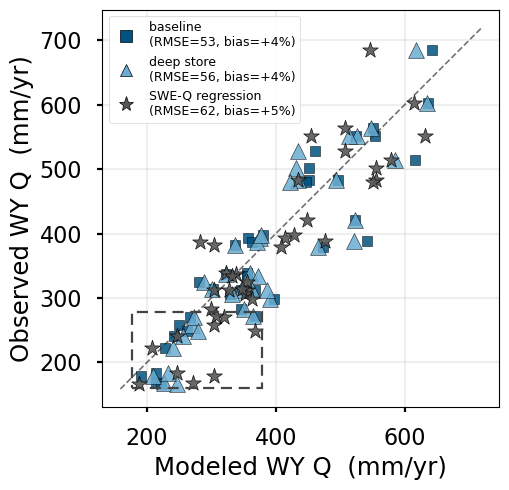

In [9]:
# ---- East scatter: modeled (x) vs observed (y) annual Q -------------------------------
# Uses the SAME plot_annual_q_scatter helper as the Tuolumne panel and both zooms. This
# cell used to re-implement the scatter by hand, which is how it drifted out of step --
# it hardcoded color='black', s=130 for the SWE-Q star instead of SWE_COLOR/SWE_MARKER,
# so restyling the palette silently missed this one panel.
plt.style.use("seaborn-v0_8-poster")
fig, ax = plt.subplots(figsize=(6, 5))
plot_annual_q_scatter(obs_wy_series, annual_q_dict, snotel_apr1_swe['value'], obs_reg,
                      basin="East River",
                      combos=("baseline", "deep store"),
                      highlight_wys={},          # e.g. {2019: "#E65100"} to ring a year
                      legend_fontsize=9, ax=ax)
ax.set_xlabel("Modeled WY Q  (mm/yr)")
ax.set_ylabel("Observed WY Q  (mm/yr)")

# call-out: the lowest observed quartile, expanded in the panel below
east_lowq_wys, east_lowq_thresh, east_lowq_bbox = bottom_quartile_subset(
    obs_wy_series, annual_q_dict, snotel_apr1_swe['value'], obs_reg)

east_highq_wys, east_highq_thresh, east_highq_bbox = top_quartile_subset(
    obs_wy_series, annual_q_dict, snotel_apr1_swe['value'], obs_reg)
add_quartile_callout(ax, east_lowq_bbox, label='')
plt.tight_layout()
plt.show()


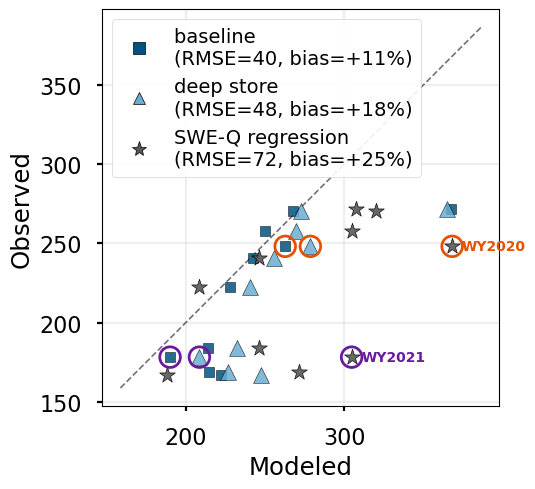

In [10]:
# ---- East: lowest observed quartile, expanded -----------------------------------------
# Same axes and styling as above, restricted to the driest 25% of water years. Metrics in
# the legend are recomputed on this subset, so they answer "how do the runs do in dry
# years" rather than being dominated by the wet end of the record.
plt.style.use("seaborn-v0_8-poster")
fig, ax = plt.subplots(figsize=(6,5))
plot_annual_q_scatter(obs_wy_series.loc[east_lowq_wys], annual_q_dict,
                      snotel_apr1_swe['value'], obs_reg, basin="East River",
                      highlight_wys={2020: "#E65100", 2021: "#6A1B9A"}, ax=ax,
                      title=f"East River — lowest observed quartile "
                            f"(< {east_lowq_thresh:.0f} mm/yr, n={len(east_lowq_wys)})")
plt.ylabel("Observed")
plt.xlabel("Modeled")
# turn off legend
# plt.legend().set_visible(False)
plt.tight_layout()
plt.show()


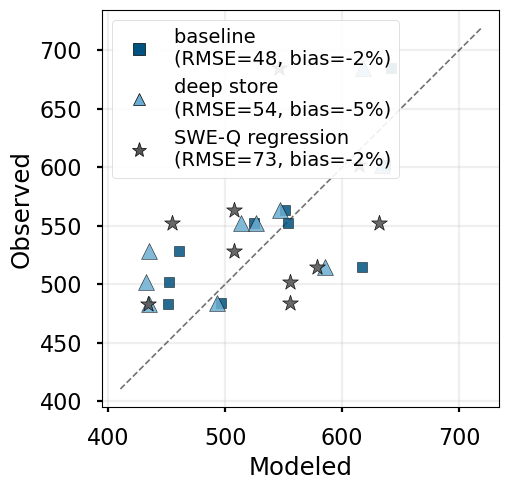

In [11]:
# ---- East: lowest observed quartile, expanded -----------------------------------------
# Same axes and styling as above, restricted to the driest 25% of water years. Metrics in
# the legend are recomputed on this subset, so they answer "how do the runs do in dry
# years" rather than being dominated by the wet end of the record.
plt.style.use("seaborn-v0_8-poster")
fig, ax = plt.subplots(figsize=(6,5))
plot_annual_q_scatter(obs_wy_series.loc[east_highq_wys], annual_q_dict,
                      snotel_apr1_swe['value'], obs_reg, basin="East River",
                      highlight_wys={2020: "#E65100", 2021: "#6A1B9A"}, ax=ax,
                      title=f"East River — lowest observed quartile "
                            f"(< {east_lowq_thresh:.0f} mm/yr, n={len(east_highq_wys)})")
plt.ylabel("Observed")
plt.xlabel("Modeled")
# turn off legend
# plt.legend().set_visible(False)
plt.tight_layout()
plt.show()


## Tuolumne River — Observed v. Modeled streamflow with model spread

In [12]:
# ---- Tuolumne observations: Hetch Hetchy UNIMPAIRED inflow ---------------------------
# NOT observations/formatted/streamflow_obs.csv -- that file is the REGULATED downstream
# gauge (below Don Pedro/La Grange, ~2x the drainage area). HH is the record the
# calibration used, and using it for the whole period avoids the WY2007 splice that
# manufactures spurious interannual autocorrelation. See
# ess-project/utils/hh_lowflow_repair.py and the notes in result_viz_sandbox.ipynb.
TUO_DOMAIN = "Tuolumne_River"
CFS_TO_CMS = 35.3146667
HH_AREA_SCALE = 0.505111        # basin/HH area ratio; vs the real gauge: ratio 1.011, rho 0.977

def load_hh_unimpaired(path, area_scale=HH_AREA_SCALE):
    """Wide WY matrix (rows 10/1..9/30, cols 'WY 1970'.., cfs) -> daily Series in m3/s."""
    raw = pd.read_csv(path)
    raw = raw[raw["DATE"].astype(str).str.match(r"^\d{1,2}/\d{1,2}$", na=False)]   # drop footer
    out = {}
    for col in [c for c in raw.columns if c.startswith("WY ")]:
        wy = int(col.split()[1])
        vals = pd.to_numeric(raw[col].astype(str).str.replace(",", ""), errors="coerce")
        for ds, v in zip(raw["DATE"], vals):
            m, d = (int(x) for x in ds.split("/"))
            try:
                out[pd.Timestamp(wy - 1 if m >= 10 else wy, m, d)] = v
            except ValueError:
                pass                                  # 2/29 in a non-leap WY column
    s = (pd.Series(out).sort_index().dropna() / CFS_TO_CMS) * area_scale
    # the final WY column is partial (exported mid-Dec 2023); trim to whole water years
    end = pd.Timestamp(s.index[-1].year + (1 if s.index[-1].month >= 10 else 0), 9, 30)
    if end > s.index[-1]:
        end = pd.Timestamp(end.year - 1, 9, 30)
    return s.loc[:end]

tuo_obs_streamflow = load_hh_unimpaired(
    DATA_DIR / "streamflow-data" / "TuolumneRiver" / "TuolumneRiver_HH_unimpaired_19702024.csv")

tuo_basin = gpd.read_file(DATA_DIR / f"domain_{TUO_DOMAIN}_distributed_elevAspect" /
                          "shapefiles" / "catchment" /
                          f"{TUO_DOMAIN}_distributed_elevAspect_HRUs_elevation_aspect.shp")
tuo_area_m2 = tuo_basin["GRU_area"].unique()[0]

print(f"Tuolumne obs: {tuo_obs_streamflow.index.min().date()} -> "
      f"{tuo_obs_streamflow.index.max().date()} | mean {tuo_obs_streamflow.mean():.2f} m3/s "
      f"| area {tuo_area_m2/1e6:.1f} km2")


Tuolumne obs: 1969-10-01 -> 2023-09-30 | mean 15.66 m3/s | area 774.5 km2


In [13]:
# ---- Tuolumne Apr-1 SWE -> annual Q regression ---------------------------------------
tuo_snotel = pd.read_csv(DATA_DIR / f"domain_{TUO_DOMAIN}_distributed_elevAspect" /
                         "observations" / "formatted" / "snotel_swe.csv",
                         parse_dates=["date"], index_col="date")
tuo_apr1_swe = tuo_snotel[(tuo_snotel.index.month == 4) & (tuo_snotel.index.day == 1)]["value"]
tuo_apr1_swe.index = tuo_apr1_swe.index.year
tuo_apr1_swe = pd.read_csv("/scratch/dlhogan/ess-project-data/geospatial-data/snowpatch_fsca/dan_peak_swe.csv", index_col=0, comment='#')['peak_swe_mm']

tuo_annual_q = tuo_obs_streamflow.resample("YS-OCT").sum() * 3600 * 24 / tuo_area_m2 * 1000
tuo_annual_q.index = tuo_annual_q.index.year + 1          # label by the WY it ends in

tuo_swe_q = pd.DataFrame({"apr1_swe": tuo_apr1_swe, "annual_q": tuo_annual_q}).dropna()
X_t, y_t = tuo_swe_q["apr1_swe"].values.reshape(-1, 1), tuo_swe_q["annual_q"].values
tuo_reg = LinearRegression().fit(X_t, y_t)
print("Tuolumne SWE-Q Regression:")
print(f"  n = {len(tuo_swe_q)}  ({tuo_swe_q.index.min()}-{tuo_swe_q.index.max()})")
print(f"  Slope: {tuo_reg.coef_[0]:.4f}")
print(f"  Intercept: {tuo_reg.intercept_:.2f}")
print(f"  R2: {tuo_reg.score(X_t, y_t):.4f}")


Tuolumne SWE-Q Regression:
  n = 38  (1986-2023)
  Slope: 1.0311
  Intercept: -122.42
  R2: 0.8013


In [14]:
# ---- Tuolumne model runs -------------------------------------------------------------
# "deep store" here is snowpatch member m090_q089 -- drift 0.90, perennial fraction
# 0.089; selected in ess-project/utils/pick_adjusted.py as the best low-flow lag shape
# per unit of KGE lost, with the closest fSCA match and a stable store.
tuo_paths = {
    "baseline":    DATA_DIR / "streamflow-data/TuolumneRiver/TuolumneRiver_SUMMA_baseline_dailyDischarge_1981_2025.csv",
    "snowpatch": DATA_DIR / "streamflow-data/TuolumneRiver/TuolumneRiver_SUMMA_snowpatch_m090q089_dailyDischarge_1981_2025.csv",
}

tuo_annual_q_dict = {}
for _key, _p in tuo_paths.items():
    _q = (pd.read_csv(_p, parse_dates=["time"], index_col="time")["discharge"]
            .resample("YS-OCT").sum() * 3600 * 24 / tuo_area_m2 * 1000)
    _q.index = _q.index.year + 1
    _q = _q.iloc[1:-1]                       # drop the partial first/last water years
    tuo_annual_q_dict[_key] = {"annual_q": _q}
    print(f"{_key:12s} WY{_q.index.min()}-{_q.index.max()}  mean {_q.mean():.0f} mm/yr")


baseline     WY1982-2025  mean 618 mm/yr
snowpatch    WY1983-2024  mean 612 mm/yr


Tuolumne River
  common years: n=38  1986-2023
  dropped from 1986-2024: [2024]
     observed Q     missing [2024]
  SWE-Q trained on WY1993-2002: n=10  slope 1.0357  intercept -75.46
     train R2 0.599 | out-of-sample (n=28) RMSE 142.7 bias +11.8%


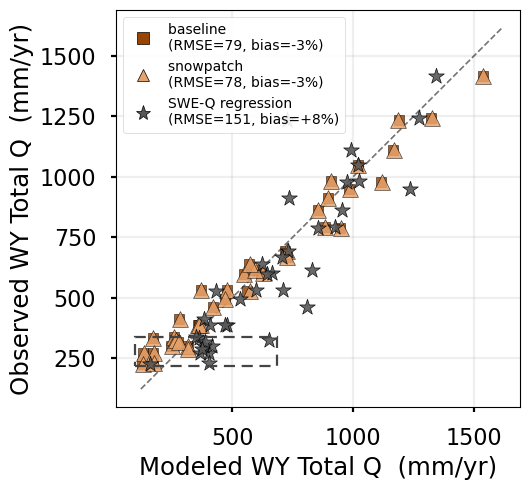

In [15]:
# ---- Tuolumne scatter ----------------------------------------------------------------
print("Tuolumne River")
tuo_years = common_years(tuo_annual_q, tuo_apr1_swe, tuo_annual_q_dict)
tuo_obs_wy_series = tuo_annual_q.loc[tuo_years]

# trained on the SAME calibration years as East (WY1993-2002) -- see the East cell
tuo_reg = fit_swe_q(tuo_swe_q)

plt.style.use("seaborn-v0_8-poster")
fig, ax = plt.subplots(figsize=(6, 5))
plot_annual_q_scatter(tuo_obs_wy_series, tuo_annual_q_dict, tuo_apr1_swe, tuo_reg,
                      basin="Tuolumne River",
                      combos=("baseline", "snowpatch"),
                      legend_fontsize=10,
                    #   highlight_wys={2020: "#E65100", 2021: "#6A1B9A"}, 
                      ax=ax)

tuo_lowq_wys, tuo_lowq_thresh, tuo_lowq_bbox = bottom_quartile_subset(
    tuo_obs_wy_series, tuo_annual_q_dict, tuo_apr1_swe, tuo_reg,
    combos=("baseline", "snowpatch"))
tuo_highq_wys, tuo_highq_thresh, tuo_highq_bbox = top_quartile_subset(
    tuo_obs_wy_series, tuo_annual_q_dict, tuo_apr1_swe, tuo_reg,
    combos=("baseline", "snowpatch"))
add_quartile_callout(ax, tuo_lowq_bbox,
                    #  label=f'lowest quartile (< {tuo_lowq_thresh:.0f} mm)'
                     )
plt.tight_layout()
plt.show()


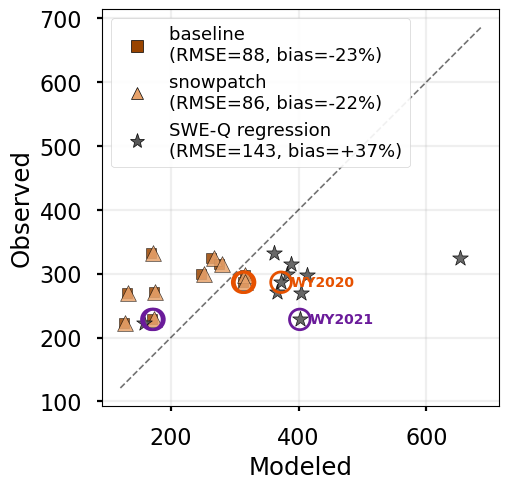

In [25]:
# ---- Tuolumne: lowest observed quartile, expanded -------------------------------------
plt.style.use("seaborn-v0_8-poster")
# Alternative approach using plt.rc
plt.rc('legend', fontsize=12)
fig, ax = plt.subplots(figsize=(6, 5))
plot_annual_q_scatter(tuo_obs_wy_series.loc[tuo_lowq_wys], tuo_annual_q_dict,
                      tuo_apr1_swe, tuo_reg, basin="Tuolumne River",
                      highlight_wys={2020: "#E65100", 2021: "#6A1B9A"}, ax=ax,
                      legend_fontsize=13,
                      combos=("baseline", "snowpatch"),
                      title=f"Tuolumne River — lowest observed quartile "
                            f"(< {tuo_lowq_thresh:.0f} mm/yr, n={len(tuo_lowq_wys)})")
plt.ylabel("Observed")
plt.xlabel("Modeled")
plt.tight_layout()
plt.show()


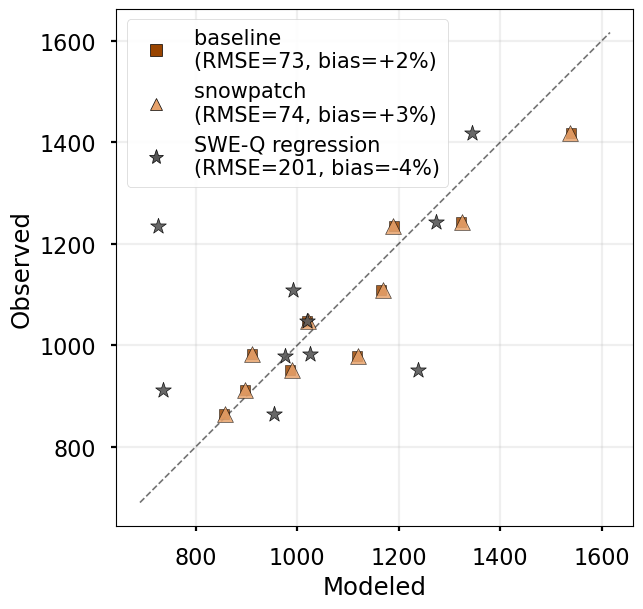

In [17]:
# ---- Tuolumne: lowest observed quartile, expanded -------------------------------------
plt.style.use("seaborn-v0_8-poster")
# Alternative approach using plt.rc
plt.rc('legend', fontsize=18)
fig, ax = plt.subplots(figsize=(7, 6.2))
plot_annual_q_scatter(tuo_obs_wy_series.loc[tuo_highq_wys], tuo_annual_q_dict,
                      tuo_apr1_swe, tuo_reg, basin="Tuolumne River",
                      highlight_wys={2020: "#E65100", 2021: "#6A1B9A"}, ax=ax,
                      legend_fontsize=15,
                      combos=("baseline", "snowpatch"),
                      title=f"Tuolumne River — lowest observed quartile "
                            f"(< {tuo_lowq_thresh:.0f} mm/yr, n={len(tuo_highq_wys)})")
plt.ylabel("Observed")
plt.xlabel("Modeled")
plt.tight_layout()
plt.show()
